# Inferencia IV débil: auditoría reproducible

## Resumen
Wald rechaza 11,60% con instrumento débil; Anderson–Rubin 4,97%, nivel nominal 5%. Con exclusión inválida, AR rechaza 87,27% aunque β verdadero=1: no corrige invalidez. Evidencia sintética, no estimación empírica.

## Lectura de los resultados ejecutados

Se contrastaron AR y Wald, inversión en un grid y un escenario heterocedástico. Las tablas distinguen relevancia, exclusión y aproximaciones asintóticas.

Resultados académicos adicionales (valores del experimento):

```json
{
  "AR_polynomial_decisions_checked": 1500,
  "topologies": [
    "recta completa",
    "recta completa",
    "intervalo"
  ]
}
```

Datos sintéticos. Esta sección acompaña las salidas guardadas y no es una medición comercial o bancaria.

## Contexto y método

El laboratorio vecino ya estudia estimadores IV inestables; aquí contrastamos inferencia puntual. $x_i=c z_i/\sqrt n+v_i$, $y_i=\beta x_i+u_i+\gamma z_i$, con $\operatorname{Corr}(u_i,v_i)=0.8$.

### Supuestos
IID normal homoscedástico y z independiente de (u,v). Para γ=0, bajo H₀:β=β₀, $r=y-\beta_0x=u$; el t² de la pendiente de r sobre [1,z] tiene distribución F(1,n−2). AR no divide por primera etapa. Wald usa β̂=(z′y)/(z′x), varianza estructural estimada y aproximación normal, vulnerable a debilidad. No invertimos el test en intervalos.

Hipótesis predefinida: AR 5%±2 puntos en los tres escenarios válidos; distorsión de Wald c=1 al menos 5 puntos mayor. γ=0,2 es falsación negativa, no hipótesis causal alternativa.

In [1]:
import json
from pathlib import Path
from IPython.display import display, Image
from src.inference import ar_pvalue, sample
root = Path.cwd()
result = json.loads((root / "results/summary.json").read_text())
print(json.dumps(result["config"], ensure_ascii=False, indent=2))

{
  "seed": 20261023,
  "replications": 3000,
  "n": 250,
  "rho": 0.8,
  "beta_null": 1.0,
  "alpha": 0.05,
  "hypothesis": "Valid AR rejection within .05 +/-.02; weak Wald distortion exceeds AR by >=.05",
  "scenarios": [
    {
      "name": "Sin relevancia",
      "strength": 0.0,
      "exclusion": 0.0
    },
    {
      "name": "Débil c=1",
      "strength": 1.0,
      "exclusion": 0.0
    },
    {
      "name": "Fuerte c=10",
      "strength": 10.0,
      "exclusion": 0.0
    },
    {
      "name": "Exclusión inválida",
      "strength": 1.0,
      "exclusion": 0.2
    }
  ]
}


## Datos y trazabilidad
12.000 réplicas sintéticas guardadas, 3.000 por escenario, n=250. Mismas semillas/shocks entre métodos y escenarios. Fuente: generador local; sin datos personales o de terceros. Configuración y hash se guardan en JSON; las tasas AR válidas coinciden exactamente por usar mismos u,z bajo H₀. No son tres muestras independientes.

In [2]:
import csv
rows = list(csv.DictReader((root / "results/replications.csv").open()))
assert len(rows) == 12000
for summary in result["summaries"]:
    print(summary["scenario"], "AR", round(100*summary["ar_rejection"], 3), "Wald", round(100*summary["wald_rejection"],3), "SE MC AR", round(summary["ar_mc_se"],5))
print("SHA256 datos:", result["data_sha256"])

Sin relevancia AR 4.967 Wald 14.167 SE MC AR 0.00397
Débil c=1 AR 4.967 Wald 11.6 SE MC AR 0.00397
Fuerte c=10 AR 4.967 Wald 4.967 SE MC AR 0.00397
Exclusión inválida AR 87.267 Wald 35.333 SE MC AR 0.00609
SHA256 datos: 09ac9489bcaa5908f09662d210839fc1a7b3f326709276de820b422259565a12


## Resultados
Barras: tasas de rechazo; errores ±1,96 SE Monte Carlo entre réplicas, no incertidumbre empírica sobre una población real. Todas las nulas β=1 son verdaderas; la exclusión inválida rompe el momento utilizado por los tests.

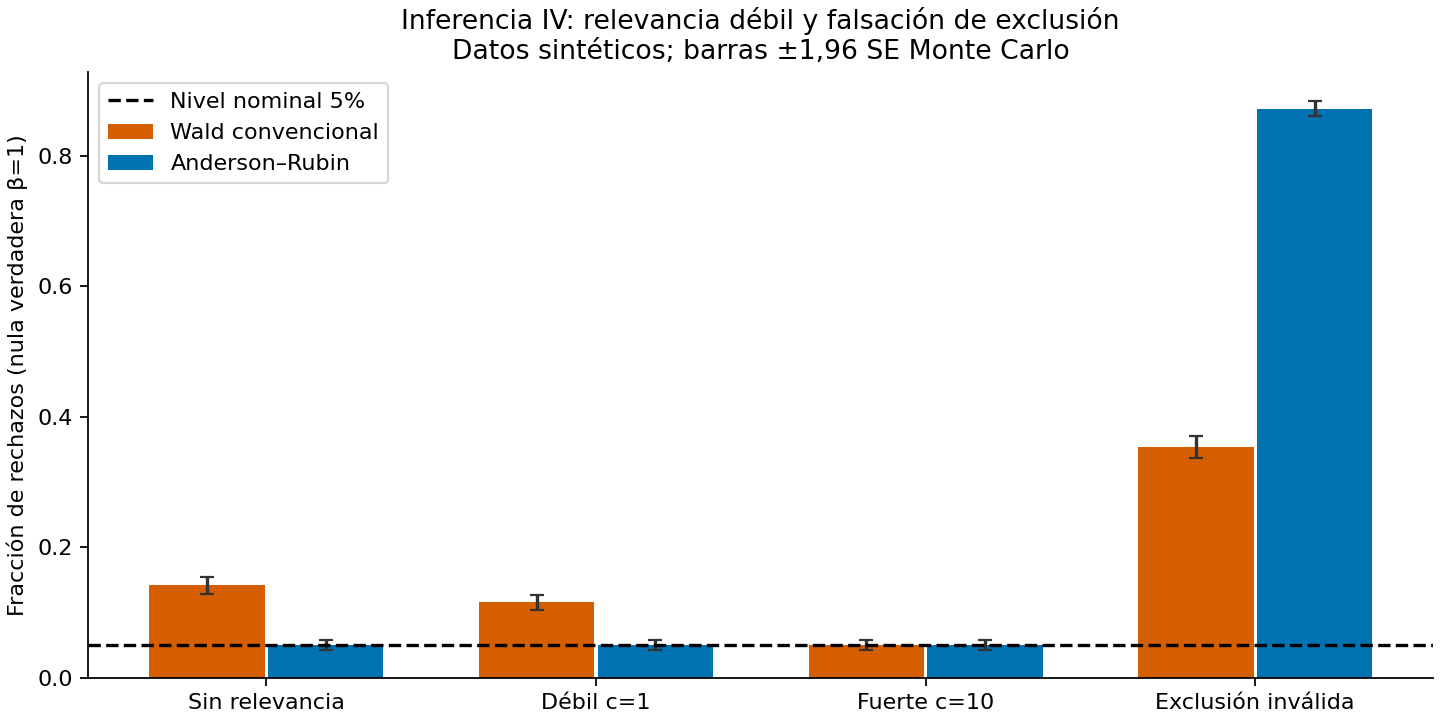

In [3]:
display(Image(filename=str(root / "results/rejection_rates.png")))

## Comprobación independiente y criterios
Comprobar un p-valor AR contra regresión reducida directa y contrastar hipótesis con resultados guardados. No convierte simulación en prueba general.

In [4]:
from scipy.stats import linregress
y, x, z = sample(12, 100, 1)
assert abs(ar_pvalue(y,x,z,1)-linregress(z,y-x).pvalue) < 1e-12
valid = result["summaries"][:3]
assert all(abs(s["ar_rejection"]-.05) <= .02 for s in valid)
weak = valid[1]
assert abs(weak["wald_rejection"]-.05)-abs(weak["ar_rejection"]-.05) >= .05
print("Criterios confirmados en esta corrida; no validación empírica.")

Criterios confirmados en esta corrida; no validación empírica.


## Conclusiones y límites
Preferir inferencia válida ante relevancia débil no resuelve identificación económica. Con instrumento válido fuerte la mejora en tamaño desaparece; con exclusión inválida el test AR también falla. No cubre poder, heteroscedasticidad, autocorrelación, clustering ni conjuntos invertidos no acotados/desconectados. S2 local; no elevar el programa. Ver informe y cinco referencias bibliográficas.

Ejecución: secuencial en IPython en proceso limpio, sin kernel Jupyter; outputs persistidos y errores abortan. El entorno restringido puede prohibir sockets de kernels.

## Laboratorio ampliado — derivación, usos y refutación

Experimentos adicionales del 23 de octubre de 2026. Datos sintéticos; las cifras guardadas del estudio original se conservan y las nuevas se recalculan debajo.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(8,4.6),'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
BLUE='#245B83'; GOLD='#B57A21'; GRAY='#4D5358'
rng_depth=np.random.default_rng(20261023)

### Modelo, identificación y unidades

$$x_i=\pi z_i+v_i,\quad y_i=\beta x_i+u_i+\gamma z_i,\quad E[z_iu_i]=0.$$

$\beta$ mide unidades de $y$ por unidad de $x$; $\pi$ es relevancia; $\gamma=0$ expresa exclusión. La correlación entre $u$ y $v$ hace endógeno a $x$. Dividir por una primera etapa casi nula vuelve inestable a IV. Anderson–Rubin prueba $H_0:\beta=b$ mediante la regresión de $y-bx$ sobre $1,z$.

$$F_{AR}(b)=\frac{SSR_0(b)-SSR_1(b)}{SSR_1(b)/(n-2)}\sim F_{1,n-2}.$$

La distribución exacta requiere errores estructurales IID normales homocedásticos y exclusión válida. La robustez a relevancia débil no sustituye estos supuestos.

### Reconstrucción independiente del estadístico

Contrastar sumas de cuadrados con la implementación evita confiar solo en el gráfico guardado.

In [6]:
from src.inference import sample, ar_pvalue, wald_pvalue, first_stage_f
from scipy.stats import f
y_d,x_d,z_d=sample(42,150,1.)
b_null=1.
residual=y_d-b_null*x_d
Z=np.column_stack([np.ones(len(z_d)),z_d])
fit=Z@np.linalg.lstsq(Z,residual,rcond=None)[0]
sse=float(np.sum((residual-fit)**2)); sst=float(np.sum((residual-residual.mean())**2))
f_manual=max(0,sst-sse)/(sse/(len(y_d)-2))
p_manual=float(f.sf(f_manual,1,len(y_d)-2))
assert abs(p_manual-ar_pvalue(y_d,x_d,z_d,1.))<1e-10
print({'F_AR':f_manual,'p_value':p_manual,'F_primera_etapa':first_stage_f(x_d,z_d)})

{'F_AR': 0.3139539888665505, 'p_value': 0.5761111110962059, 'F_primera_etapa': 2.532125706148759}


### Inversión del test y conjunto de confianza

El grid no certifica los límites exactos: un conjunto puede ser desconectado, ilimitado o vacío. No reducirlo automáticamente a una banda entre mínimo y máximo.

c= 0.0 fracción del grid aceptada= 0.14701803051317613 toca frontera= False
c= 8.0 fracción del grid aceptada= 0.05131761442441054 toca frontera= False


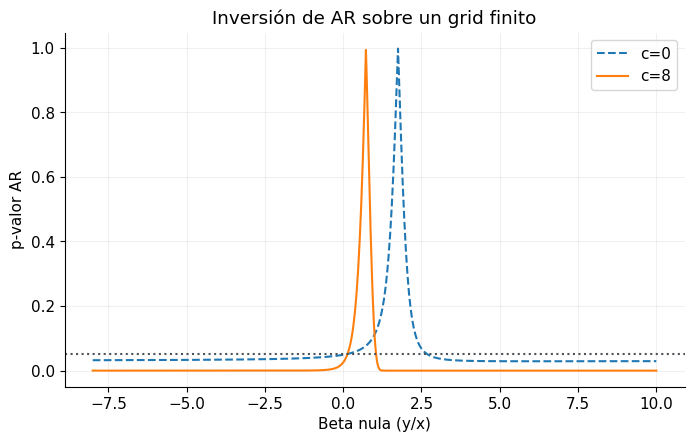

In [7]:
grid_beta=np.linspace(-8,10,721)
fig,ax=plt.subplots()
for strength,style in [(0.,'--'),(8.,'-')]:
    yy,xx,zz=sample(51,150,strength)
    pvals=np.array([ar_pvalue(yy,xx,zz,b) for b in grid_beta])
    ax.plot(grid_beta,pvals,label=f'c={strength:g}',ls=style)
    accepted=grid_beta[pvals>.05]
    print('c=',strength,'fracción del grid aceptada=',len(accepted)/len(grid_beta),
          'toca frontera=', bool(len(accepted) and (accepted[0]==grid_beta[0] or accepted[-1]==grid_beta[-1])))
ax.axhline(.05,color=GRAY,ls=':'); ax.set(xlabel='Beta nula (y/x)',ylabel='p-valor AR',title='Inversión de AR sobre un grid finito');ax.legend();plt.show()

### Relevancia y exclusión son preguntas distintas

Repeticiones nuevas con semillas separadas del estudio original. Las barras muestran tasas Monte Carlo, no cobertura de una cartera real.

,c,gamma,AR,Wald,AR_lo,AR_hi
0,0,0.00,0.0667,0.1417,0.0342,0.1261
1,1,0.00,0.0667,0.0917,0.0342,0.1261
2,8,0.00,0.0667,0.0583,0.0342,0.1261
3,1,0.35,0.9917,0.3000,0.9543,0.9985


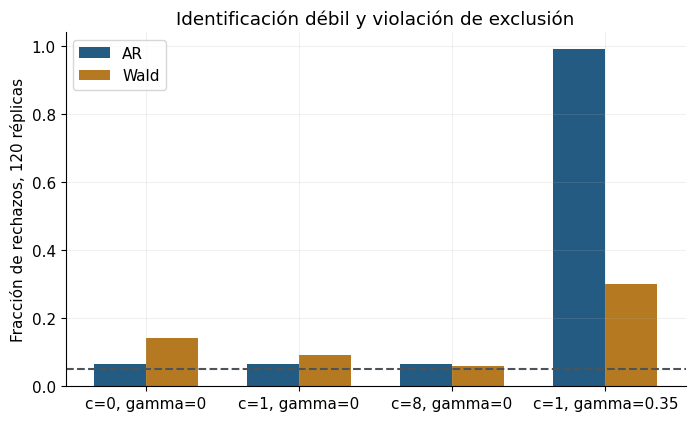

In [8]:
from scipy.stats import binomtest
records=[]
for strength,gamma in [(0,0),(1,0),(8,0),(1,.35)]:
    rejected_ar=[];rejected_w=[]
    for seed in range(120):
        yy,xx,zz=sample(50000+seed,150,strength,exclusion=gamma)
        rejected_ar.append(ar_pvalue(yy,xx,zz,1.)<=.05)
        rejected_w.append(wald_pvalue(yy,xx,zz,1.)<=.05)
    lohi=binomtest(sum(rejected_ar),120).proportion_ci(method='wilson')
    records.append({'c':strength,'gamma':gamma,'AR':np.mean(rejected_ar),'Wald':np.mean(rejected_w),'AR_lo':lohi.low,'AR_hi':lohi.high})
checks_iv=pd.DataFrame(records);display(checks_iv.round(4))
fig,ax=plt.subplots();pos=np.arange(len(records))
ax.bar(pos-.17,checks_iv.AR,.34,label='AR',color=BLUE)
ax.bar(pos+.17,checks_iv.Wald,.34,label='Wald',color=GOLD)
ax.set_xticks(pos,[f'c={r["c"]}, gamma={r["gamma"]}' for r in records]);ax.axhline(.05,color=GRAY,ls='--')
ax.set(ylabel='Fracción de rechazos, 120 réplicas',title='Identificación débil y violación de exclusión');ax.legend();plt.show()

### Escala e invariancia

Cambiar unidades de x y la hipótesis de beta de forma consistente debe conservar AR.

In [9]:
original=ar_pvalue(y_d,x_d,z_d,1.)
converted=ar_pvalue(y_d,100*x_d,z_d,.01)
assert abs(original-converted)<1e-12
assert abs(original-ar_pvalue(y_d,x_d,-3*z_d,1.))<1e-12
print('Invariancia de unidades e instrumento verificada.')

Invariancia de unidades e instrumento verificada.


### Uso y próxima falsificación

Usar AR para hipótesis estructurales con exclusión defendible, no para resolver instrumentos inválidos. Reportar el conjunto invertido completo y la primera etapa. Próximo experimento: heterocedasticidad con inferencia robusta y su comparación contra este F exacto; no atribuir a este notebook esa garantía pendiente.

### Preguntas para extender el estudio

1. ¿Qué supuesto permite el resultado y qué contraejemplo lo destruye?
2. ¿Qué cambia al separar entrenamiento, calibración y evaluación por fecha?
3. ¿Qué pérdidas, costos o acciones no están representados?
4. ¿Qué evidencia real haría abandonar este modelo?

Las salidas anteriores son el resultado de esta ejecución; las pruebas locales no establecen validez empírica.

### Heterocedasticidad: límite del F exacto

El contraste robusto usa una covarianza sandwich HC1 con aproximación normal. No es una garantía finita ni la misma distribución F del experimento homocedástico.

In [10]:
from scipy.stats import norm
hetero_rows=[]
for amplitude in [0.,1.,3.]:
    exact_reject=0
    robust_reject=0
    for seed in range(200):
        local=np.random.default_rng(90000+seed)
        zz=local.normal(size=200)
        vv=local.normal(size=200)
        noise=local.normal(size=200)
        uu=(1+amplitude*np.abs(zz))*noise
        xx=zz/np.sqrt(200)+vv
        yy=xx+uu
        exact_reject+=ar_pvalue(yy,xx,zz,1.)<=.05
        design=np.column_stack([np.ones(200),zz])
        inv=np.linalg.inv(design.T@design)
        coef=inv@design.T@(yy-xx)
        resid=yy-xx-design@coef
        meat=design.T@(resid[:,None]**2*design)
        cov=inv@meat@inv*200/198
        p_hc1=2*norm.sf(abs(coef[1]/np.sqrt(cov[1,1])))
        robust_reject+=p_hc1<=.05
    hetero_rows.append({'amplitud':amplitude,'F_homocedastico':exact_reject/200,'HC1_asintotico':robust_reject/200})
display(pd.DataFrame(hetero_rows))

,amplitud,F_homocedastico,HC1_asintotico
0,0.0,0.035,0.04
1,1.0,0.185,0.05
2,3.0,0.245,0.04


### Incertidumbre Monte Carlo

Los intervalos Wilson describen incertidumbre de estas 120 repeticiones por escenario. Un estimado cercano a 5% no prueba igualdad exacta.

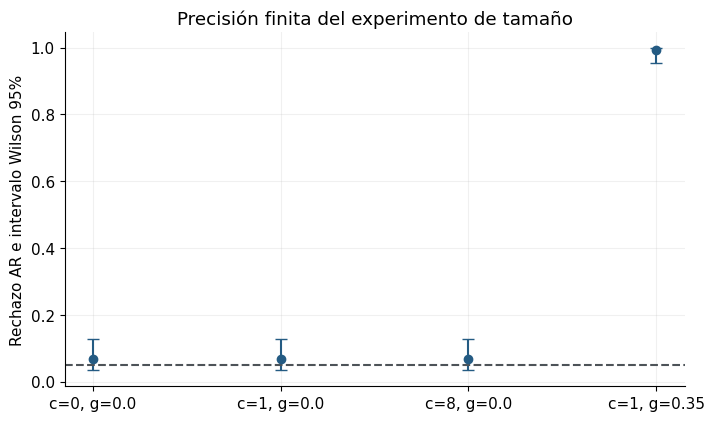

In [11]:
fig,ax=plt.subplots()
centers=checks_iv.AR.to_numpy()
lower=checks_iv.AR_lo.to_numpy()
upper=checks_iv.AR_hi.to_numpy()
ax.errorbar(np.arange(len(centers)),centers,yerr=[centers-lower,upper-centers],fmt='o',color=BLUE,capsize=4)
ax.axhline(.05,color=GRAY,ls='--')
ax.set_xticks(range(len(centers)),[f'c={x.c}, g={x.gamma}' for x in checks_iv.itertuples()])
ax.set(ylabel='Rechazo AR e intervalo Wilson 95%',title='Precisión finita del experimento de tamaño')
plt.show()

### Primera etapa y dispersión del estimador

La razón IV puede ser extrema aun con datos finitos. Se reportan cuantiles, sin recortar los valores antes de calcularlos.

In [12]:
estimates=[]
for strength in [0.,1.,8.]:
    sample_est=[]
    for seed in range(300):
        yy,xx,zz=sample(300000+seed,150,strength)
        zc=zz-zz.mean()
        denom=float(zc@(xx-xx.mean()))
        if denom!=0:
            sample_est.append(float(zc@(yy-yy.mean()))/denom)
    values=np.array(sample_est)
    estimates.append({'c':strength,'q01':np.quantile(values,.01),'mediana':np.median(values),'q99':np.quantile(values,.99),'max_abs':np.max(np.abs(values))})
display(pd.DataFrame(estimates).round(3))

,c,q01,mediana,q99,max_abs
0,0.0,-6.083,1.852,18.964,67.485
1,1.0,-9.543,1.325,6.573,182.071
2,8.0,0.614,1.003,1.245,1.291


### Interpretación de las pruebas adicionales

Cada experimento modifica un supuesto concreto. Las comparaciones conservan denominadores, unidades y desconocidos; los resultados negativos forman parte de la evidencia. Las simulaciones no convierten un diseño en un sistema operativo ni sustituyen validación independiente con datos aprobados.

## Ampliación académica: literatura, fórmulas y experimento

Consulta bibliográfica del 23 de octubre de 2026. Se distingue método publicado, derivación propia y experimento sintético. El [mapa bibliográfico](https://github.com/Jose85100/Portafolio/blob/research/2026-10-23-multi-domain-cycle/reviews/2026-10-23-academic/README.md) en la raíz del repositorio registra publicaciones, acceso y brechas; las fuentes específicas se enlazan debajo.

### Inversión algebraica de Anderson–Rubin

Base: [Anderson y Rubin, 1949](https://www.jstor.org/stable/2236803). Alternativa pendiente: [Moreira, Econometrica 2003](https://doi.org/10.1111/1468-0262.00438). No se implementa CLR ni se atribuye a CLR la siguiente inversión de AR.

Con variables centradas, $r_b=y-bx$, $P_z=zz'/z'z$, $M_z=I-P_z$ y $c=F^{-1}_{1,n-2}(1-\alpha)$:

$$\mathcal C_{AR}=\{b:(n-2)r_b'P_zr_b-c\,r_b'M_zr_b\le0\}.$$

Equivale a $Ab^2+Bb+C\le0$. Para $h=n-2+c$:

$$A=h(z'x)^2/(z'z)-cx'x,$$
$$B=-2h(z'y)(z'x)/(z'z)+2cy'x,\quad C=h(z'y)^2/(z'z)-cy'y.$$

Esta es nuestra expansión algebraica del test. La aceptación puede ser un intervalo, dos rayos, toda la recta o vacío. Las raíces numéricas no son un certificado de aritmética exacta.

### Topología del conjunto, sin truncarlo al grid

Se inspeccionan todas las raíces reales. Casos casi degenerados requieren diagnóstico de precisión y no se etiquetan como intervalos regulares.

In [13]:
from scipy.stats import f as f_distribution
paper_rng=np.random.default_rng(2301)
def ar_polynomial(y,x,z,alpha=.05):
    yy,xx,zz=[v-np.mean(v) for v in (y,x,z)]
    critical=f_distribution.ppf(1-alpha,1,len(y)-2)
    h=len(y)-2+critical
    zy=float(zz@yy);zx=float(zz@xx);z2=float(zz@zz)
    return np.array([h*zx*zx/z2-critical*float(xx@xx),
                     -2*h*zy*zx/z2+2*critical*float(yy@xx),
                     h*zy*zy/z2-critical*float(yy@yy)])

def quadratic_topology(coef):
    a,b,c=coef
    scale=max(1.,float(np.max(np.abs(coef))))
    if abs(a)<1e-12*scale:return 'degenerado: revisar',[]
    discriminant=b*b-4*a*c
    if discriminant<0:return ('recta completa' if a<0 else 'vacio'),[]
    roots=np.sort(np.roots(coef).real)
    return ('intervalo' if a>0 else 'dos rayos'),roots.tolist()

poly_rows=[]
for strength in [0.,1.,8.]:
    yy,xx,zz=sample(312,150,strength)
    coef=ar_polynomial(yy,xx,zz)
    topology,roots=quadratic_topology(coef)
    comparison=np.r_[np.linspace(-20,20,400),[-1e6,1e6]]
    via_poly=np.polyval(coef,comparison)<=0
    via_test=np.array([ar_pvalue(yy,xx,zz,b)>=.05 for b in comparison])
    assert np.array_equal(via_poly,via_test)
    poly_rows.append({'strength':strength,'topologia':topology,'raices':roots})
display(pd.DataFrame(poly_rows))

,strength,topologia,raices
0,0.0,recta completa,[]
1,1.0,recta completa,[]
2,8.0,intervalo,"[0.3901660781128176, 1.0662203176040927]"


### Verificación aleatoria y raíces fuera del rango visible

Se comparan decisiones algebraicas y p-valores en 30 muestras nuevas; no se confunde un extremo del gráfico con un límite de confianza.

In [14]:
agreements=0
for seed in range(30):
    yy,xx,zz=sample(1000000+seed,80,seed%5)
    coef=ar_polynomial(yy,xx,zz)
    candidates=paper_rng.uniform(-50,50,50)
    direct=np.array([ar_pvalue(yy,xx,zz,b)>=.05 for b in candidates])
    assert np.array_equal(np.polyval(coef,candidates)<=0,direct)
    agreements+=len(candidates)
print('Decisiones contrastadas:',agreements)
import json
print('ACADEMIC_METRICS:'+json.dumps({'AR_polynomial_decisions_checked':agreements,'topologies':[x['topologia'] for x in poly_rows]}))

Decisiones contrastadas: 1500
ACADEMIC_METRICS:{"AR_polynomial_decisions_checked": 1500, "topologies": ["recta completa", "recta completa", "intervalo"]}


### Qué falta para completar esta línea

La inversión anterior cierra la limitación del grid para este modelo. Siguen pendientes CLR, varios instrumentos, robustez HAC/clustering, potencia bajo alternativas y una aplicación con exclusión defendible. La lectura de Moreira se verificó en metadatos y resumen editorial; no se reprodujo su algoritmo.